<a href="https://colab.research.google.com/github/juleuzun/Python_DataScience_Bootcamp/blob/main/Assignment/Assignment_7_K_Means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Dataset loading

In [4]:
data_url = "https://raw.githubusercontent.com/juleuzun/Python_DataScience_Bootcamp/refs/heads/main/Datasets/Assignment_7_Customer_segmentation.csv"
data = pd.read_csv(data_url)

data.head()

,annual_income,spending_score
0,16.8,88.3
1,45.6,40.3
2,44.7,49.1
3,87.7,92.7
4,34.1,81.0


# Inspecting the dataset

In [5]:
print(data.head())
print(data.info())
print(data.describe())


   annual_income  spending_score
0           16.8            88.3
1           45.6            40.3
2           44.7            49.1
3           87.7            92.7
4           34.1            81.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   annual_income   250 non-null    float64
 1   spending_score  250 non-null    float64
dtypes: float64(2)
memory usage: 4.0 KB
None
       annual_income  spending_score
count     250.000000      250.000000
mean       52.419600       50.694000
std        26.256596       26.560065
min        11.300000        1.000000
25%        26.325000       25.450000
50%        53.150000       48.900000
75%        78.175000       76.675000
max       107.000000       97.300000


# Feature selection

In [6]:
X = data[['annual_income', 'spending_score']]
print(X.head())

   annual_income  spending_score
0           16.8            88.3
1           45.6            40.3
2           44.7            49.1
3           87.7            92.7
4           34.1            81.0


#Feature scaling with StandardScaler

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(
    X_scaled,
    columns=['annual_income', 'spending_score']
)
X_scaled.head()

,annual_income,spending_score
0,-1.359318,1.418725
1,-0.260250,-0.392124
2,-0.294596,-0.060135
3,1.346373,1.584720
4,-0.699114,1.143325


# Elbow Method

In [9]:
k_values = range(1,11)

inertia_list = []

for k in k_values:
  kmeans = KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10

  )
  kmeans.fit(X_scaled)
  inertia_list.append(kmeans.inertia_)

# Elbow Method Graph

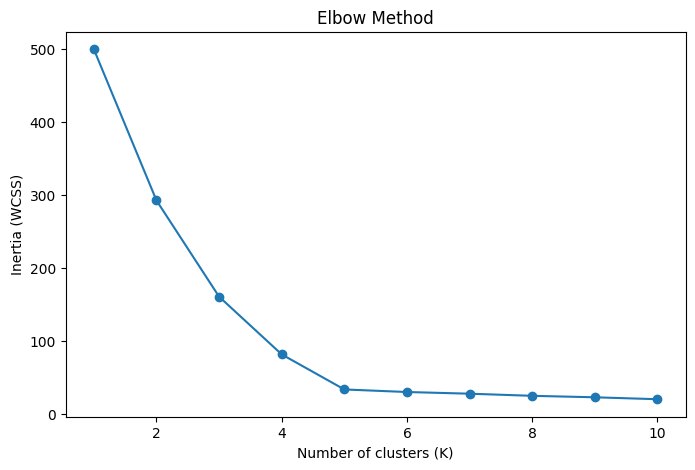

In [10]:
plt.figure(figsize=(8,5))

plt.plot(
    k_values,
    inertia_list,
    marker='o'
)

plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method')

plt.show()

#Creating the K-Means model

In [11]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10

)

kmeans.fit(X_scaled)

KMeans(n_clusters=5, n_init=10, random_state=42)

# Analyzing cluster characteristics

In [12]:
data['Cluster'] = kmeans.labels_
data.head()

,annual_income,spending_score,Cluster
0,16.8,88.3,3
1,45.6,40.3,4
2,44.7,49.1,4
3,87.7,92.7,1
4,34.1,81.0,3


# Cluster centers

In [15]:
centers = kmeans.cluster_centers_
print(centers)

[[ 1.09290061 -1.16113201]
 [ 1.04638927  1.22047877]
 [-1.1062268  -0.96457935]
 [-1.05692141  0.93930291]
 [ 0.00299035 -0.05967335]]


# Rescaling back to actual values

In [16]:
centers_actual = scaler.inverse_transform(centers)
centers_df = pd.DataFrame(
    centers_actual,
    columns=['annual_income', 'spending_score']
)

print(centers_df)

   annual_income  spending_score
0      81.058000       19.916000
1      79.839216       83.045098
2      23.432000       25.126000
3      24.724000       75.592000
4      52.497959       49.112245


# Visualizing Clusters

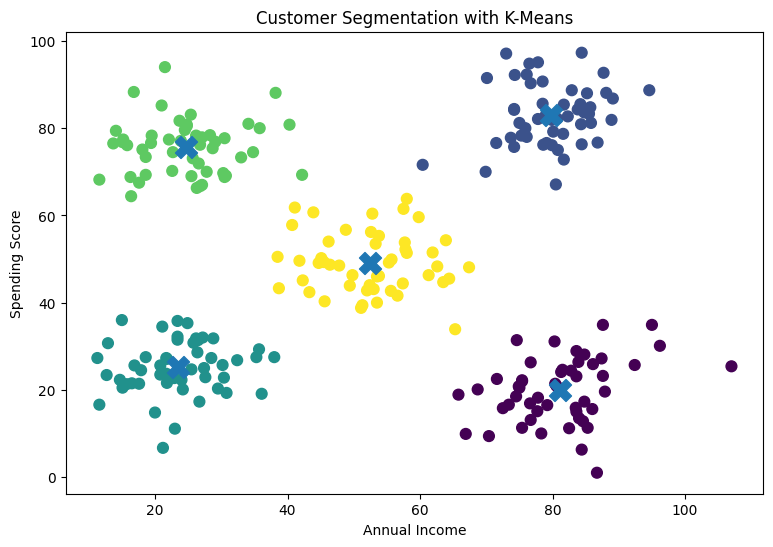

In [19]:
plt.figure(figsize=(9,6))

plt.scatter(
    data['annual_income'],
    data['spending_score'],
    c=data['Cluster'],
    s=60
)

plt.scatter(
    centers_actual[:,0],
    centers_actual[:,1],
    marker='X',
    s=250
)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Customer Segmentation with K-Means')

plt.show()

# Analyzing cluster distribution

In [18]:
print(data['Cluster'].value_counts().sort_index())

Cluster
0    50
1    51
2    50
3    50
4    49
Name: count, dtype: int64


# Making cluster centers more interpretable

In [20]:
centers_df['Cluster'] = centers_df.index

centers_df = centers_df[
    ['Cluster', 'annual_income', 'spending_score']
]
print(centers_df)

   Cluster  annual_income  spending_score
0        0      81.058000       19.916000
1        1      79.839216       83.045098
2        2      23.432000       25.126000
3        3      24.724000       75.592000
4        4      52.497959       49.112245


# Silhouette Score

In [21]:
from sklearn.metrics import silhouette_score

silhouette = silhouette_score(
    X_scaled,
    data['Cluster']

)

print("Silhouette Score: ", silhouette)

Silhouette Score:  0.6800509512917465
